# Этап 2. Одномерный анализ (EDA)

**Цель:** понять распределение каждого признака по отдельности.

**Что смотрим:**
- `SalePrice` — форма распределения, скос, диапазон.
- Числовые признаки — гистограммы, KDE, skew, доля нулей.
- Категориальные — частоты, доминирующие категории.
- Почти-константы — колонки, где одна категория занимает > 95%.

**Данные:** `data/train_clean.csv`, `data/test_clean.csv` (после этапа 1).

In [2]:
import json
import numpy as np
import pandas as pd 
import matplotlib.pyplot as plt
import seaborn as sns



In [3]:
pd.set_option("display.max_columns", 100)
pd.set_option("display.float_format", "{:.2f}".format)

sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (10,6)
plt.rcParams["figure.dpi"] = 100


### Шаг 2.0. Загрузка данных



In [4]:
train = pd.read_csv("../data/train_clean.csv")
test = pd.read_csv("../data/test_clean.csv")

print("train:", train.shape)
print("test:", test.shape)
print()

print("Пропусков в train: ", train.isna().sum().sum())
print("Пропусков в test: ", test.isna().sum().sum())



train: (1460, 81)
test: (1459, 80)

Пропусков в train:  7480
Пропусков в test:  7536


#### Есть пропуски!!!!

In [5]:
# загрузка списка колонок 

with open("../columns_info.json") as f:
    cols_info = json.load(f)
    
target = cols_info["target"]
pure_num_cols = cols_info["pure_num_cols"]      
pseudo_num_cols = cols_info["pseudo_num_cols"]  
cat_cols = cols_info["cat_cols"] 


print(f"Целевая: {target}")
print(f"Числовых: {len(pure_num_cols)}")
print(f"Псевдочисловых: {len(pseudo_num_cols)}")
print(f"Категориальных: {len(cat_cols)}")

Целевая: SalePrice
Числовых: 33
Псевдочисловых: 3
Категориальных: 43


### Шаг 2.1. Анализ SalePrice — целевая переменная

Смотрим описательные статистики, скос, гистограмму, логарифмирование.

In [6]:
# Описательные статистики SalePrice
# describe() — count, mean, std, min, 25%, 50%, 75%, max

print("SalePrice — описательные статистики:")

print(train[target].describe().round(2))

print()


# Skewness — асимметрия
# > 0 — правый скос (длинный хвост справа)
# ~ 0 — симметрично

print(f"Skewness: {train[target].skew():.3f}")


# Kurtosis — «толщина» хвостов
# > 0 — тяжёлые хвосты (выбросы)

print(f"Kurtosis: {train[target].kurt():.3f}")

SalePrice — описательные статистики:
count     1460.00
mean    180921.20
std      79442.50
min      34900.00
25%     129975.00
50%     163000.00
75%     214000.00
max     755000.00
Name: SalePrice, dtype: float64

Skewness: 1.883
Kurtosis: 6.536


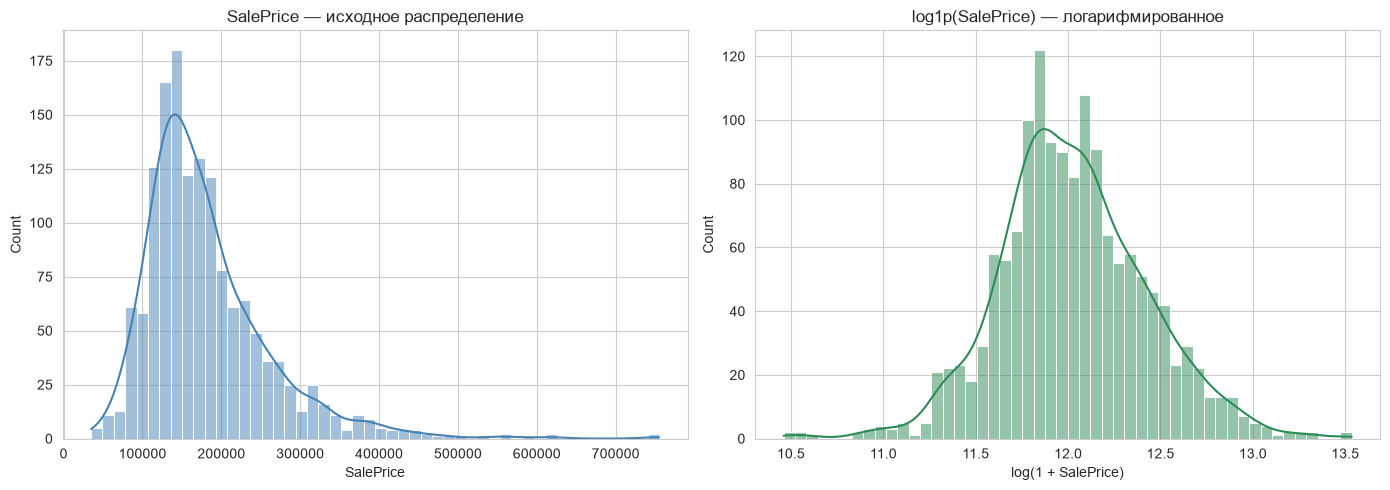

In [7]:
# гистограмма SalePrice


fig, axes = plt.subplots(1, 2, figsize = (14, 5)) # 1 строка, 2 столбца 

# Левая — исходный SalePrice
# histplot с kde=True — гистограмма + кривая плотности

sns.histplot(train[target], kde = True, ax = axes[0], bins = 50, color = "steelblue")

# KDE- KDE-кривая (Kernel Density Estimate) — сглаженная оценка плотности распределения поверх гистограммы
# bins -  Количество столбцов (корзин) гистограммы

axes[0].set_title("SalePrice — исходное распределение")
axes[0].set_xlabel("SalePrice")



# Правая — log1p(SalePrice)
# np.log1p(x) = log(1 + x) — безопасен для нулей

sns.histplot(np.log1p(train[target]), kde = True, ax= axes[1], bins = 50, color = "seagreen")
axes[1].set_title("log1p(SalePrice) — логарифмированное")
axes[1].set_xlabel("log(1 + SalePrice)")

plt.tight_layout()
plt.show()




In [8]:
# Сравниваем skew исходного и логарифмированного SalePrice
# Если log1p сильно уменьшает skew — распределение нормализуется

print(f"Skew исходный: {train[target].skew():.3f}")
print(f"Skew log1p: {np.log1p(train[target]).skew():.3f}")

# Вывод - логарифм значительно нормализовал распределение 

Skew исходный: 1.883
Skew log1p: 0.121


### Вывод по 2.1

- SalePrice имеет **правый скос**, так как среднее > медианы, skew = 1.88
- Логарифмирование номализует распределение 
- Длинный правый хвост означает наличие дорогих домов 

## Шаг 2.2. Распределения числовых признаков


Строим гистограммы по всем 33 числовым признакам.
Ищем: скос, диапазон, нули, бимодальность.

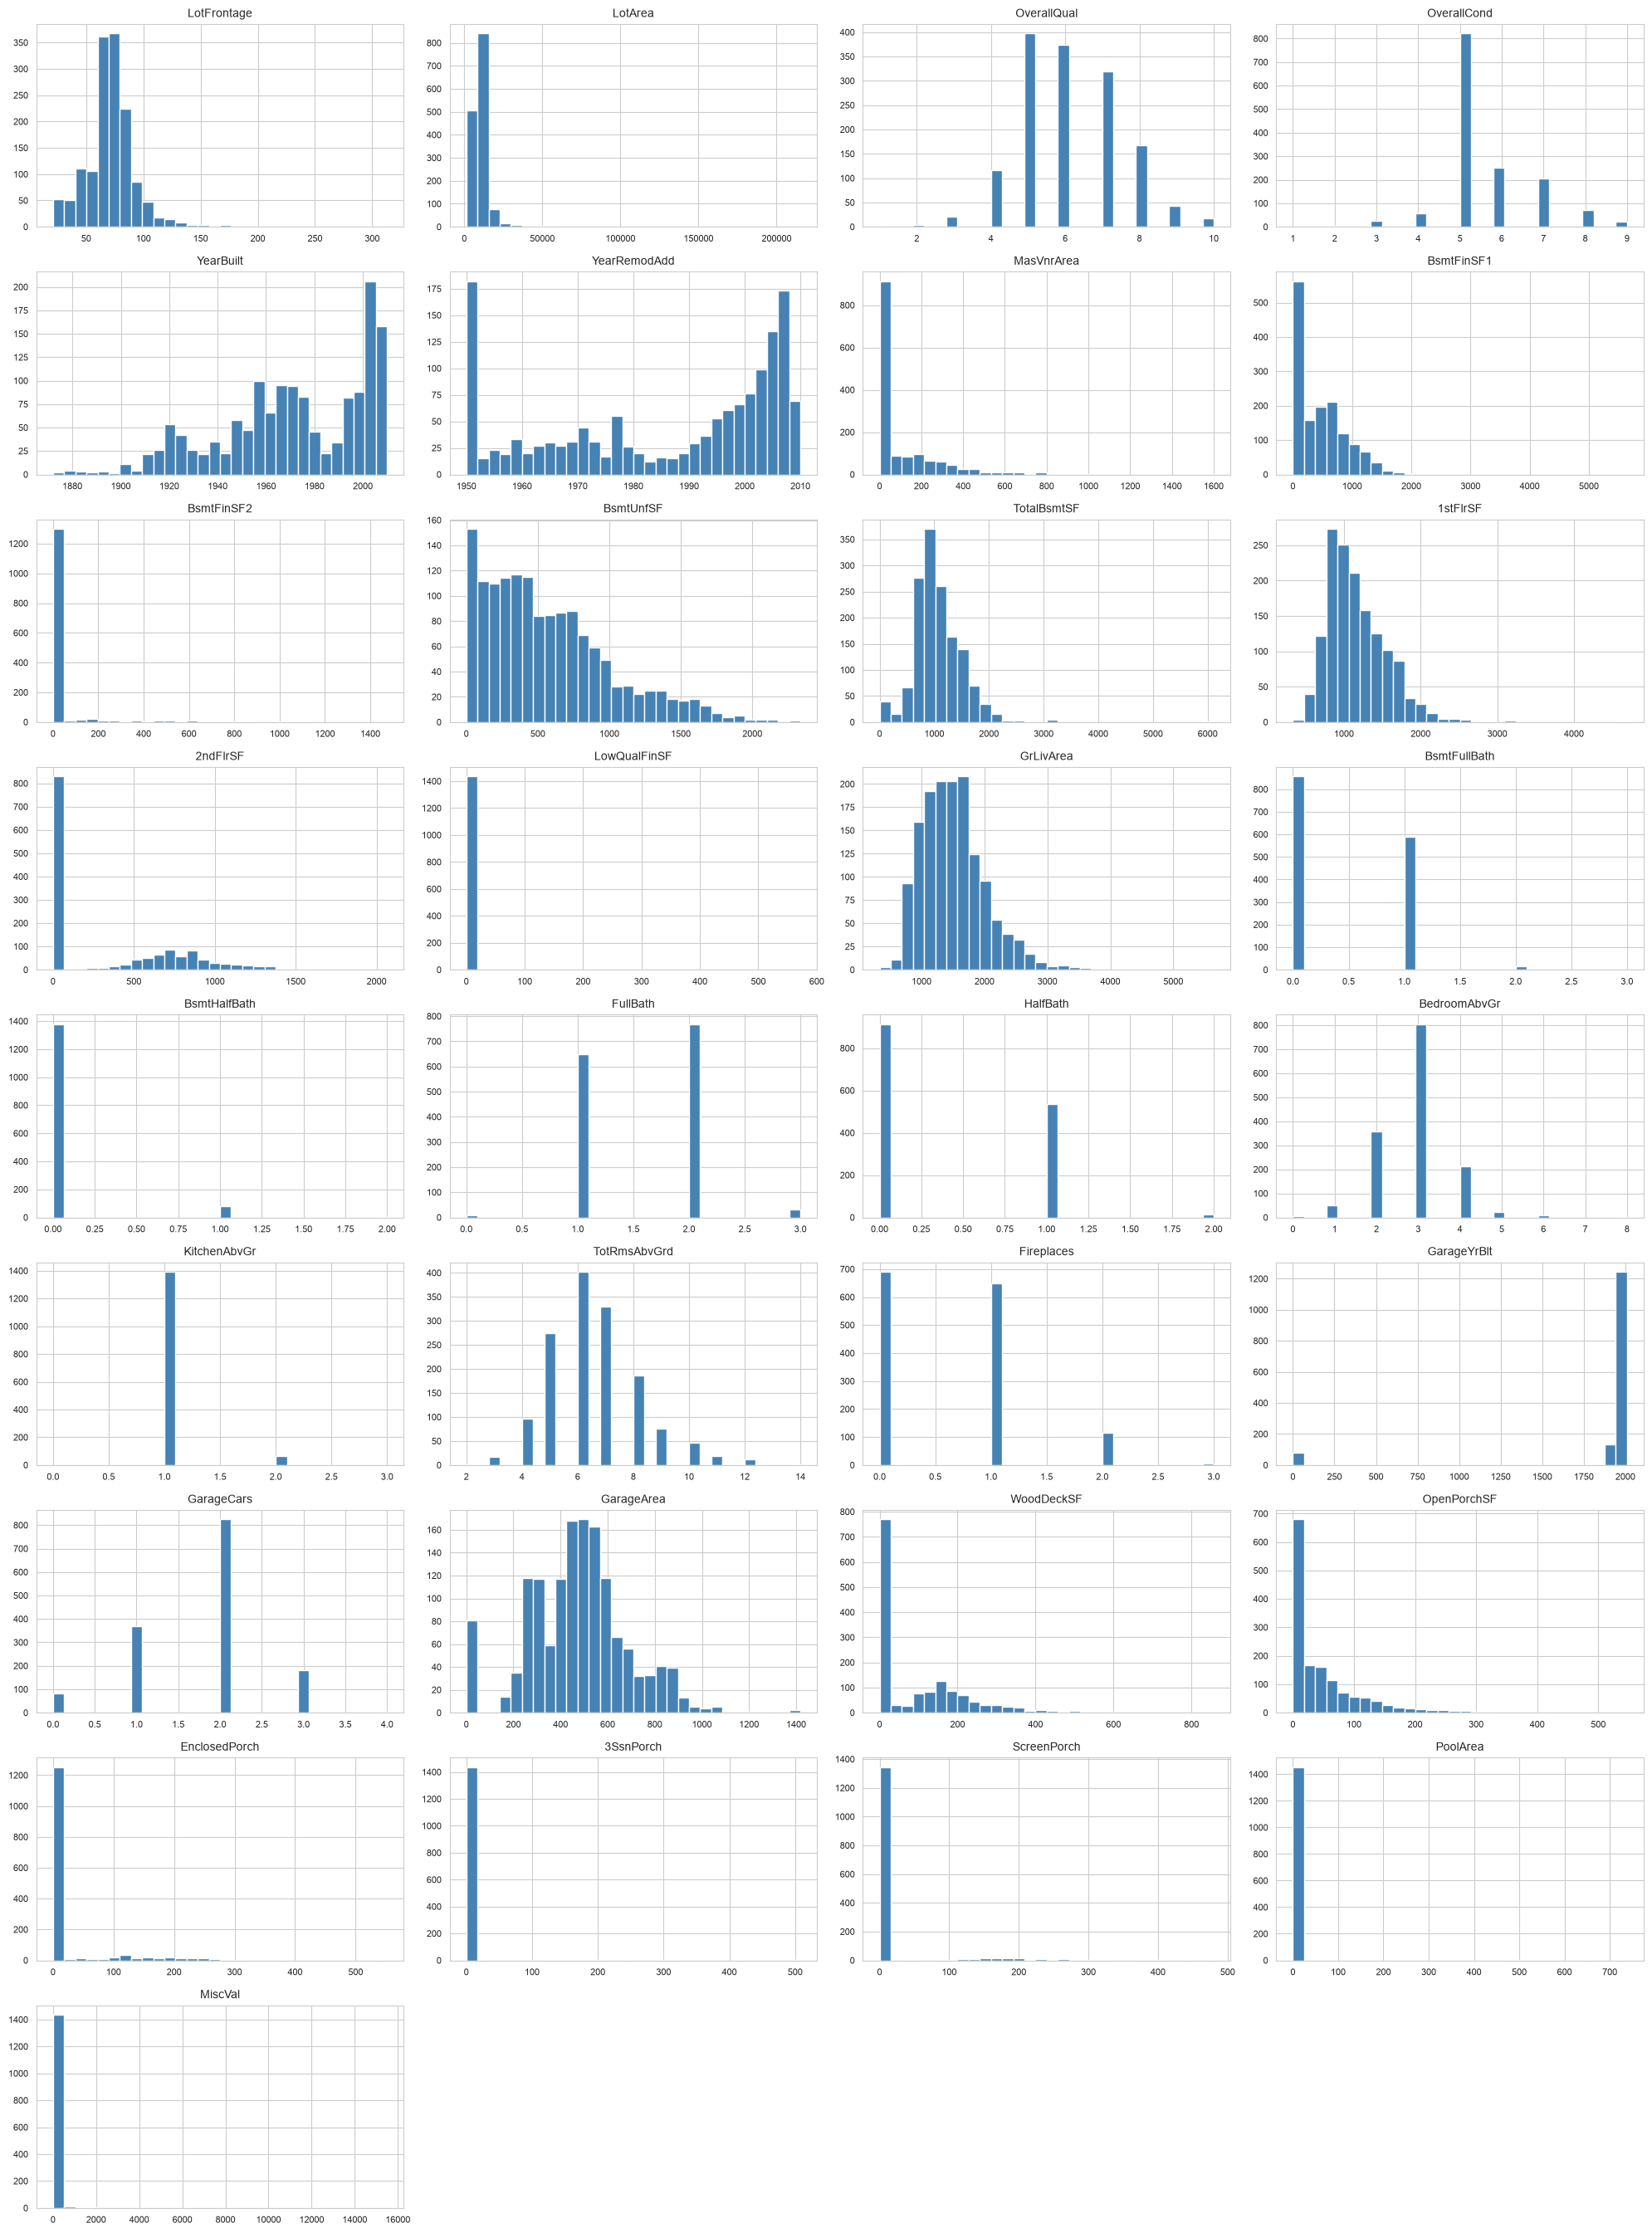

In [9]:
# Сетка гистограмм по всем числовым признакам

n_cols = 4 # количество колонок в сетке 

n_rows = (len(pure_num_cols) + n_cols - 1)// n_cols # количество строк округляем вверх 

fig, axes = plt.subplots(n_rows, n_cols, figsize = (20, n_rows *3))
axes  = axes.ravel() # превращаем 2D-массив в 1D


# Проход по каждой числовой колонке 

for i, col in enumerate(pure_num_cols):
    axes[i].hist(train[col], bins = 30, color = "steelblue", edgecolor = "white")
    axes[i].set_title(col, fontsize = 10)
    axes[i].tick_params(labelsize= 8)


# Скрываем пустые subplots

for i in range(len(pure_num_cols), len(axes)):
    axes[i].axis("off")

plt.tight_layout()
plt.show()

In [10]:
# Считаем skew для каждого числового признака
# sort_values(ascending=False) — от большего к меньшему

skew_vals = train[pure_num_cols].skew().sort_values(ascending = False)

print("=== Топ-10 с наибольшим скосом ===")

print(skew_vals.head(10).round(2))
print()
print("=== Топ-10 с наименьшим скосом ===")
print(skew_vals.tail(10).round(2))

=== Топ-10 с наибольшим скосом ===
MiscVal         24.48
PoolArea        14.83
LotArea         12.21
3SsnPorch       10.30
LowQualFinSF     9.01
KitchenAbvGr     4.49
BsmtFinSF2       4.26
ScreenPorch      4.12
BsmtHalfBath     4.10
EnclosedPorch    3.09
dtype: float64

=== Топ-10 с наименьшим скосом ===
Fireplaces      0.65
BsmtFullBath    0.60
OverallQual     0.22
BedroomAbvGr    0.21
GarageArea      0.18
FullBath        0.04
GarageCars     -0.34
YearRemodAdd   -0.50
YearBuilt      -0.61
GarageYrBlt    -3.87
dtype: float64


In [11]:
# Считаем долю нулей в каждом числовом признаке

zero_share = (train[pure_num_cols] == 0).mean().sort_values(ascending = False)

# (train[pure_num_cols] == 0) — True/False
# .mean() — доля True = доля нулей

print("=== Топ-10 по доле нулей ===")
print(zero_share.head(10).round(3))

=== Топ-10 по доле нулей ===
PoolArea        0.99
3SsnPorch       0.98
LowQualFinSF    0.98
MiscVal         0.96
BsmtHalfBath    0.94
ScreenPorch     0.92
BsmtFinSF2      0.89
EnclosedPorch   0.86
HalfBath        0.62
MasVnrArea      0.59
dtype: float64


### Вывод по 2.2


- Большинство числовых колонок имеют **правый скос**
- Топ по скосу: MiscVal, PoolArea, LotArea, 3SsnPorch, LowQualFinSF 
- 6 колонок с долей нулей > 90%: PoolArea, 3SsnPorch, LowQualFinSF, MiscVal, BsmtHalfBath, ScreenPorch  



### Шаг 2.3. Распределения категориальных признаков

Смотрим: сколько уникальных категорий, какая доминирует.

In [12]:
# Сбор сводки по категориальным колонкам 

cat_summary = pd.DataFrame({
    "n_unique": train[cat_cols].nunique(),
                            "top": [train[c].mode().iloc[0] for c in cat_cols], 
                            "top_freq": [train[c].value_counts().iloc[0] for c in cat_cols]
                            }) 

# n_unique() - число уникальных категорий
# mode().iloc[0] — самая частая категория
  # value_counts().iloc[0] — частота самой частой категории 

# Доля топ-категории от всех строк

cat_summary["top_share"] = (cat_summary["top_freq"]/ len(train)).round(3)

# Сортируем — сверху самые «доминантные»

cat_summary = cat_summary.sort_values("top_share", ascending = False)
cat_summary


,n_unique,top,top_freq,top_share
Utilities,2,AllPub,1459,1.00
Street,2,Pave,1454,1.00
Condition2,8,Norm,1445,0.99
RoofMatl,8,CompShg,1434,0.98
Heating,6,GasA,1428,0.98
LandSlope,3,Gtl,1382,0.95
CentralAir,2,Y,1365,0.94
Functional,7,Typ,1360,0.93
PavedDrive,3,Y,1340,0.92
Electrical,5,SBrkr,1335,0.91


In [13]:
# Фильтруем почти-константы: top_share > 0.95

# Почти-константа (almost constant) — это признак (столбец), у которого одно значение встречается подавляюще часто, а все остальные — крайне редко. То есть столбец почти не меняется от строки к строке.

almost_const = cat_summary[cat_summary["top_share"] > 0.95]

print(f"Почти констант(top_share > 0.95): {len(almost_const)}")

print()
print(almost_const[["n_unique", "top", "top_share"]])


Почти констант(top_share > 0.95): 5

            n_unique      top  top_share
Utilities          2   AllPub       1.00
Street             2     Pave       1.00
Condition2         8     Norm       0.99
RoofMatl           8  CompShg       0.98
Heating            6     GasA       0.98


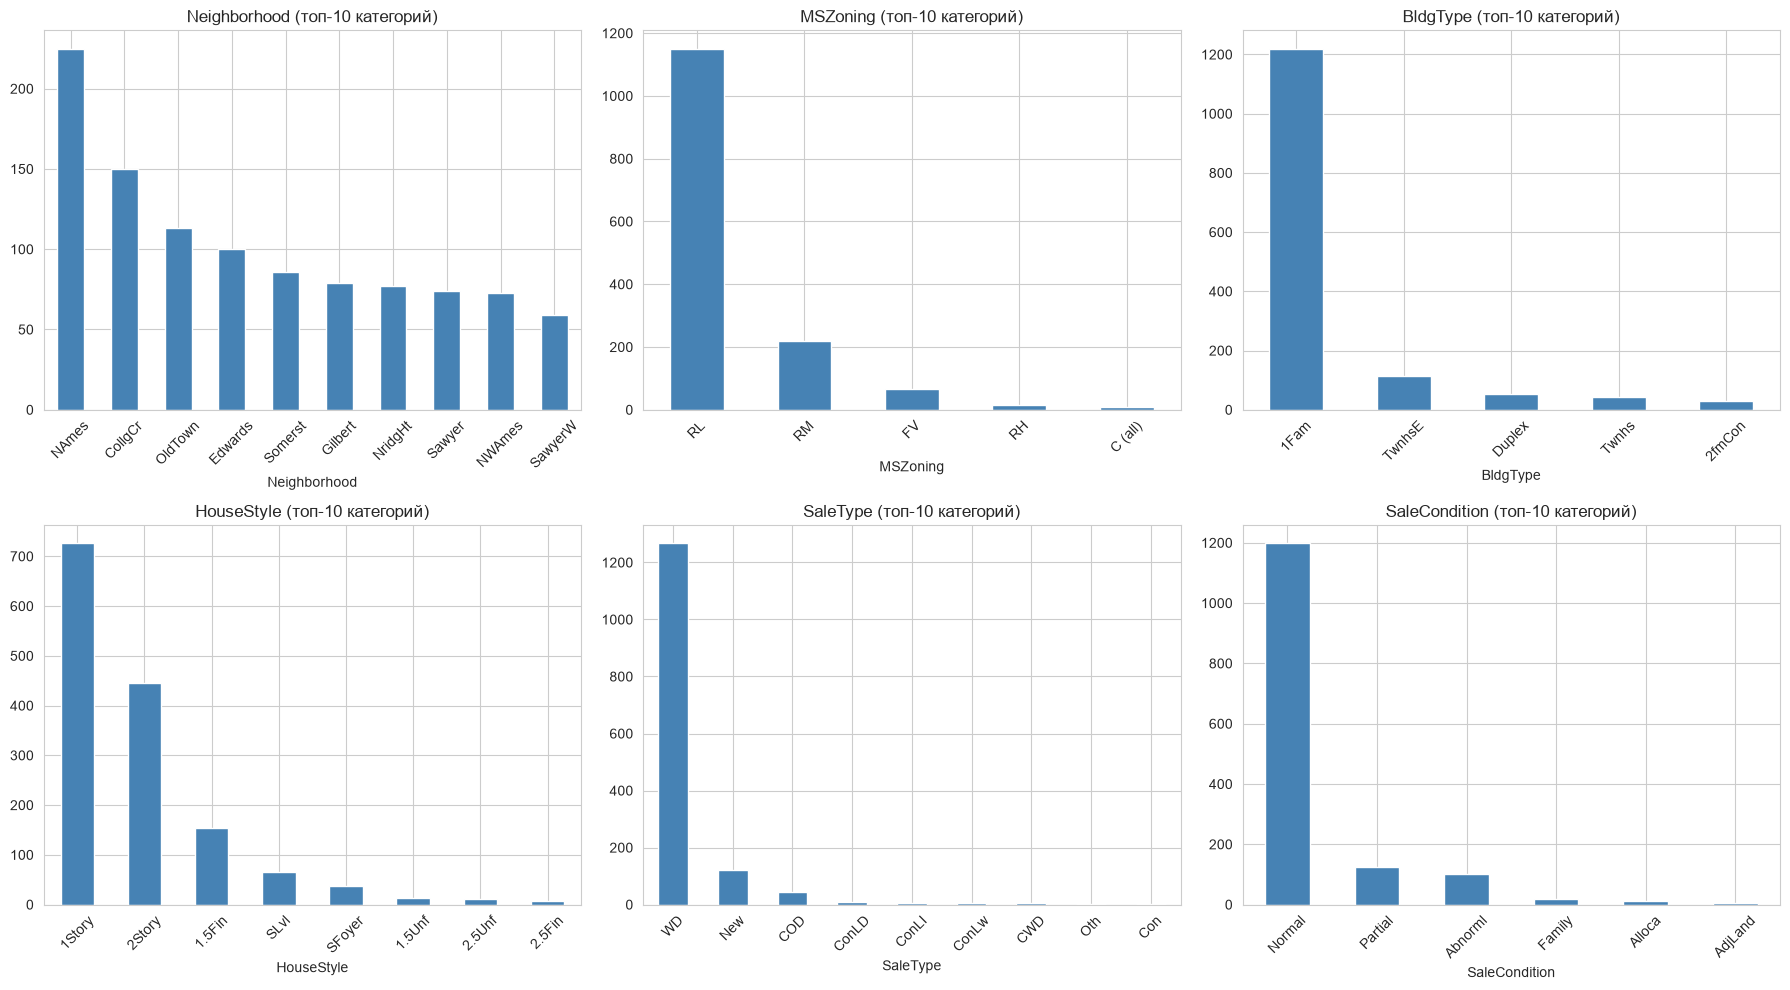

In [14]:
# Barplot по 6 категориальным признакам
# Показываем топ-10 категорий в каждом

show_cols = ["Neighborhood", "MSZoning", "BldgType", "HouseStyle",
             "SaleType", "SaleCondition"]

fig, axes = plt.subplots(2, 3, figsize = (18, 10))
axes = axes.ravel()

for i, col in enumerate(show_cols):
    counts = train[col].value_counts().head(10) # список топ-10 самых частых категорий столбца col вместе с их частотами
    counts.plot(kind = "bar", ax = axes[i], color = "steelblue")
    axes[i].set_title(f"{col} (топ-10 категорий)")
    axes[i].tick_params(axis = "x", rotation = 45)
    
plt.tight_layout()
plt.show()

### Вывод по 2.3

- **5 категориальных колонок — почти-константы** (`top_share > 0.95`): Utilities, Street, Condition2, RoofMatl, Heating 
- Neighborhood` — самая информативная колонка: 25 категорий, топ занимает только 15%.
- MSZoning, BldgType, SaleType — сильно доминирует одна категория (75–85%).

### Шаг 2.4. Поиск почти-констант среди числовых

Проверяем: есть ли числовые признаки с очень низкой вариацией.
Используем range, cv (коэффициент вариации), zero_share.

In [15]:
# Сводка по числовым признакам
# std - стандартное отклонение (мера разброса значений вокруг среднего)

num_summary = pd.DataFrame({
    "min": train[pure_num_cols].min(), 
    "max": train[pure_num_cols].max(), 
    "mean": train[pure_num_cols].mean(), 
    "std": train[pure_num_cols].std()
})

# Размах (max − min)

num_summary["range"] = num_summary["max"] - num_summary["min"]

# Коэффициент вариации (std / mean) — относительный разброс (показывает, насколько сильно значения гуляют относительно своего среднего)
num_summary["cv"] = (num_summary["std"] / num_summary["mean"]).round(3)

# Доля нулей

num_summary["zero_share"] = (train[pure_num_cols] == 0).mean().round(3)

# Сортируем по CV — сверху самые «стабильные»

num_summary.sort_values("cv").head(10)




,min,max,mean,std,range,cv,zero_share
YearRemodAdd,1950.00,2010.00,1984.87,20.65,60.00,0.01,0.00
YearBuilt,1872.00,2010.00,1971.27,30.20,138.00,0.01,0.00
OverallCond,1.00,9.00,5.58,1.11,8.00,0.20,0.00
KitchenAbvGr,0.00,3.00,1.05,0.22,3.00,0.21,0.00
OverallQual,1.00,10.00,6.10,1.38,9.00,0.23,0.00
GarageYrBlt,0.00,2010.00,1868.74,453.70,2010.00,0.24,0.06
TotRmsAbvGrd,2.00,14.00,6.52,1.63,12.00,0.25,0.00
BedroomAbvGr,0.00,8.00,2.87,0.82,8.00,0.28,0.00
LotFrontage,21.00,313.00,70.20,22.43,292.00,0.32,0.00
1stFlrSF,334.00,4692.00,1162.63,386.59,4358.00,0.33,0.00


In [16]:
# Колонки, где > 90% значений — нули

high_zero = num_summary[num_summary["zero_share"] > 0.9].sort_values("zero_share", ascending = False)

print("Колонок с zero_share > 90%:", len(high_zero))
print()
print(high_zero[["zero_share", "min", "max"]])

Колонок с zero_share > 90%: 6

              zero_share  min      max
PoolArea            0.99 0.00   738.00
3SsnPorch           0.98 0.00   508.00
LowQualFinSF        0.98 0.00   572.00
MiscVal             0.96 0.00 15500.00
BsmtHalfBath        0.94 0.00     2.00
ScreenPorch         0.92 0.00   480.00


### Итог по этапу 2

### SalePrice
- Правый скос, skew ≈ 1.88.
- log1p нормализует (skew ≈ 0.12).
- Диапазон: 34900 – 755000.

### Числовые признаки
- Большинство скошены вправо.
- Топ по скосу: MiscVal, PoolArea, 3SsnPorch.
- 5 колонок с zero_share > 90% — полезны как «есть / нет».

### Категориальные признаки
- 5 почти-констант (top_share > 0.95).
- Neighborhood — самый разнообразный (25 категорий).
- Три колонки — MSZoning, BldgType, SaleType — имеют одну сильно доминирующую категорию (78–87%), MSZoning - RL, BldgType - 1Fam, SaleType - WD

